# Exercises - lab session 5

## **Exercise #1**


1. Create a new function evalMSE2 that takes a full dataset, splits the data into a training and a validation sample, trains an OLS model to predict a response variable with a set of predictors, and returns the MSE on the validation set. Include the size of the validation set and the value of the random seed among the arguments of the function. 
2. Use this function on the `Auto` dataset to predict `mpg` using `horsepower`. Allocate 100 observations to the validation set. Estimate the validation MSE for 50 random seeds using a **for** loop, the `enumerate()` and the `range()` functions. Use $[1001, 1002, ... , 1050]$ as your random seeds. Store the 50 MSEs in an array named *MSE*. Hint: You will need to first create MSE as an array of zeros and to then update its elements one by one.
3. Plot an histogram of the MSEs using `matplotlib`'s `hist()` function.
4. Compute the standard deviation of the MSEs using the function `np.std()` with the argument `ddof=1` and the mean MSE using `np.mean()`. Then, compute the coefficient of variation of the MSEs as $CV = std / mean$. Propose an interpretation of the coefficient of variation in terms of how much the validation MSE may change depending on the random split.
5. Repeat steps 2 to 4 using 5-fold cross-validation to obtain 50 cross-validated MSEs with the same 50 random seeds ($[1001, 1002, ... , 1050]$). Compare the coefficient of variation on the 50 MSEs obtained with a single validation set to the coefficient on the 50 cross-validated MSEs. What do you observe? 

**1. Create a new function evalMSE2**

In [3]:
#Import required packages

import numpy as np
from ISLP import load_data
from ISLP.models import ModelSpec as MS
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

mkdir -p failed for path /home/onyxia/.config/matplotlib: [Errno 13] Permission denied: '/home/onyxia/.config/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-_pd5z290 because there was an issue with the default path (/home/onyxia/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [6]:
#Define function

def evalMSE2(terms,
            response,
            data,
            size,
            seed):

   
   
   train, test = train_test_split(data,
                                         test_size=size,
                                         random_state=seed)
   mm = MS(terms, intercept=True)
    
   X_train = mm.fit_transform(train)
   y_train = train[response]

   X_test = mm.transform(test)
   y_test = test[response]

   results = sm.OLS(y_train, X_train).fit()
   test_pred = results.predict(X_test)

   return np.mean((y_test - test_pred)**2)

**2. Import Auto data and estimate MSE for 50 random seeds**

In [10]:
import warnings
warnings.filterwarnings('ignore', message='ModelSpec will move')

Auto = load_data('Auto')
MSE = np.zeros(50)
for idx, value in enumerate(range(1001, 1051)):
    MSE[idx] = evalMSE2(['horsepower'],
                       'mpg',
                       Auto,
                       100,
                       value)
MSE

array([21.94286579, 28.35459675, 23.96290477, 24.50351495, 24.9560475 ,
       22.9161657 , 21.79943941, 25.98782384, 23.40561425, 27.22793146,
       21.39318407, 18.75236134, 20.06907824, 23.23575546, 22.34353708,
       26.61099101, 20.68598741, 23.0408166 , 24.74493721, 18.34733744,
       18.14965658, 19.8922133 , 26.22692528, 22.96432568, 25.84347059,
       27.84205504, 29.0448302 , 23.12563311, 33.96590879, 28.09976506,
       22.2364668 , 22.3433159 , 23.83141111, 24.46302767, 20.99514385,
       27.68408549, 25.0915312 , 22.28358296, 30.04037454, 25.96528019,
       22.0346582 , 23.90734761, 28.3050094 , 23.59311389, 21.63012637,
       18.61555003, 21.9386263 , 23.17937246, 24.79611711, 22.21944282])

**3. Plot an histogram of the MSEs**

(array([ 4.,  4., 11., 12.,  8.,  3.,  6.,  1.,  0.,  1.]),
 array([18.14965658, 19.7312818 , 21.31290702, 22.89453224, 24.47615746,
        26.05778269, 27.63940791, 29.22103313, 30.80265835, 32.38428357,
        33.96590879]),
 <BarContainer object of 10 artists>)

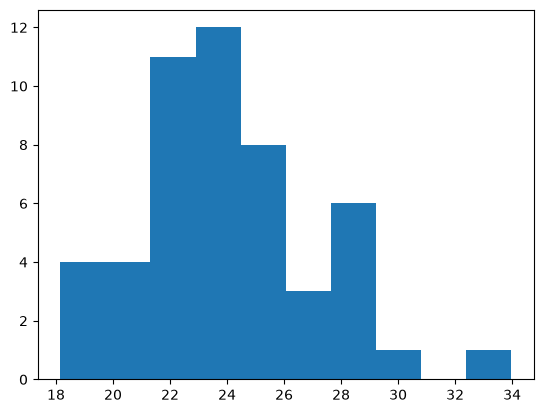

In [8]:
plt.hist(MSE)

**4. Compute the coefficient of variation of the MSEs**

In [20]:
std_mse = np.std(MSE, ddof=1)
print(std_mse)
mean_mse = np.mean(MSE)
print(mean_mse)
CoV_mse = std_mse/mean_mse*100
print("The MSEs obtained with the validation set method have a coefficient of variation of:", CoV_mse.round(2), "%.")

3.2121726696891595
23.89178515578629
The MSEs obtained with the validation set method have a coefficient of variation of: 13.44 %.


**5. Repeat steps 2 to 4 using 5-fold cross-validation**

In [17]:
#Import required packages
from ISLP.models import sklearn_sm
from sklearn.model_selection import \
     (cross_validate,
      KFold)


#Define function

def evalMSE3(response,
            data,
            splits,
            seed):

   
   cv = KFold(n_splits=splits,
           shuffle=True,
           random_state=seed)

   X, Y = data.drop(columns=[response]), Auto[response]

   M = sklearn_sm(sm.OLS)
    
   M_CV = cross_validate(M,
                         X,
                         Y,
                        cv=cv)
    
   cv_error = np.mean(M_CV['test_score'])

   return cv_error

In [18]:
# Obtain 50 cross-validated MSEs

CV_MSE = np.zeros(50)
for idx, value in enumerate(range(1001, 1051)):
    CV_MSE[idx] = evalMSE3('mpg',
                       Auto,
                       5,
                       value)
CV_MSE

array([11.96076094, 11.68441953, 11.57640294, 12.12549724, 11.64725643,
       11.61861453, 11.99543206, 11.78798688, 11.83288099, 11.56978865,
       11.77776322, 11.79242034, 11.69531047, 11.65701825, 12.01150534,
       11.72379566, 11.7926084 , 12.1113446 , 11.86439596, 11.57394988,
       11.79190491, 12.21150949, 11.73200025, 11.92900511, 11.68362241,
       11.75028678, 12.21107468, 11.68986214, 12.22111307, 11.72003317,
       11.64253823, 12.20455991, 11.54332464, 11.6866486 , 11.63858517,
       12.15290309, 11.86392501, 11.7075146 , 11.63263508, 11.68171598,
       11.48871587, 11.56665851, 11.70541291, 11.48746792, 11.6490592 ,
       11.821732  , 11.91428259, 11.79573903, 11.72685308, 11.74159148])

(array([ 3.,  6., 13.,  7.,  7.,  3.,  3.,  1.,  2.,  5.]),
 array([11.48746792, 11.56083243, 11.63419695, 11.70756146, 11.78092598,
        11.8542905 , 11.92765501, 12.00101953, 12.07438404, 12.14774856,
        12.22111307]),
 <BarContainer object of 10 artists>)

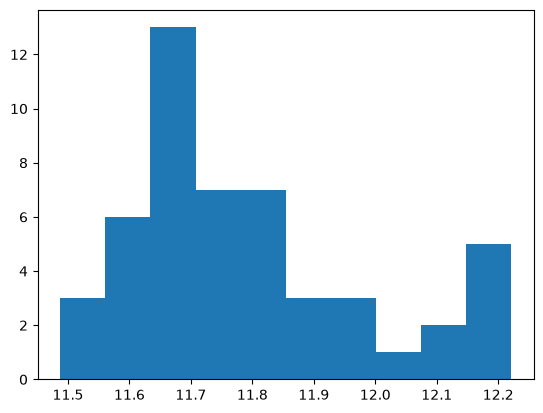

In [19]:
plt.hist(CV_MSE)

In [21]:
std_cvmse = np.std(CV_MSE, ddof=1)
print(std_cvmse)
mean_cvmse = np.mean(CV_MSE)
print(mean_cvmse)
CoV_cvmse = std_cvmse/mean_cvmse*100
print("The cross-validated MSEs obtained with 5-fold cross-validation have a coefficient of variation of:", CoV_cvmse.round(2), "%.")

0.19785313698527662
11.787828544415595
The cross-validated MSEs obtained with 5-fold cross-validation have a coefficient of variation of: 1.68 %.


###### **Exercise #2**

In this exercise, we will predict the number of applications received using the other variables in the College data set:

    (a) Split the data set into a training set and a test set.

    (b) Fit a linear model using least squares on the training set, and report the test error obtained.

    (c) Fit a ridge regression model on the training set, with lambda chosen by cross-validation. Report the test error obtained. Note: Use the `skl.ElasticNetCV()` function as shown in notebook 4. 

    (d) Fit a lasso model on the training set, with lambda chosen by cross-validation. Report the test error obtained, along with the number of non-zero coefficient estimates. Note: you just need to modify the l1_ratio argument to l1_ratio = 1 in the `skl.ElasticNetCV()` function.

    (e) Comment on the results obtained. How accurately can we predict the number of college applications received? Is there much difference among the test errors resulting from these three approaches?



In [2]:
# Required packages

import numpy as np
import pandas as pd
import statsmodels.api as sm
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from ISLP.models import sklearn_sm

In [3]:
# Import from ISLP

college = load_data('College')
print(college.shape)
college.describe()

(777, 18)


,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


### (a) Training set / test set


In [20]:
# Design matrix and train/test split

outer_valid = skm.ShuffleSplit(n_splits=1,
                               test_size=0.5,
                               random_state=1)

design = MS(college.columns.drop('Apps'))
D = design.fit_transform(college)
D = D.drop('intercept', axis=1)
X = np.asarray(D)
Y = np.array(college['Apps'])

def report(name, results):
    """Print the test RMSE of a model evaluated on outer_valid and return it."""
    rmse = np.sqrt(-results['test_score'][0])
    print(f"Test RMSE of the {name}: {rmse:.2f}")
    print(f"This is {rmse / rmse_null * 100:.2f} % of the RMSE of the null model.")
    return rmse

In [21]:
# Benchmark: null model that always predicts the training mean

results = skm.cross_validate(DummyRegressor(),
                             X,
                             Y,
                             cv=outer_valid,
                             scoring='neg_mean_squared_error')
rmse_null = np.sqrt(-results['test_score'][0])
print(f"Test RMSE of the null model: {rmse_null:.2f}")

Test RMSE of the null model: 4178.00


### (b) Least squares

In [22]:
# OLS model (no scaling needed: it does not change the least-squares fit)

ols = sklearn_sm(sm.OLS)

results = skm.cross_validate(ols,
                             X,
                             Y,
                             cv=outer_valid,
                             scoring='neg_mean_squared_error')
rmse_ols = report("OLS model", results)

Test RMSE of the OLS model: 1192.99
This is 28.55 % of the RMSE of the null model.


### (c) Ridge regression

In [16]:
# Define the lambda grid and look at the coefficient path

lambdas = 10**np.linspace(6, -4, 100) 

Xs = (X - X.mean(0)) / X.std(0)

lambdas, soln_array = skl.ElasticNet.path(Xs, 
                                    Y,
                                    l1_ratio=0,
                                    alphas=lambdas)[:2]
soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path

,Private[Yes],Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
-13.815511,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
-13.582926,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
-13.350342,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
-13.117757,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
-12.885173,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8.280003,-220.366169,3871.114278,-797.894718,875.509320,-278.354400,270.694232,67.490009,-343.320551,166.308222,3.560088,20.800457,-141.068219,-49.342449,60.929593,1.007913,406.826699,149.160281
8.512587,-220.366169,3871.114278,-797.894718,875.509320,-278.354400,270.694232,67.490009,-343.320551,166.308222,3.560088,20.800457,-141.068219,-49.342449,60.929593,1.007913,406.826699,149.160281
8.745172,-220.239462,3876.582933,-805.667450,877.422543,-279.760307,273.405304,67.558630,-344.200800,166.009209,3.510382,20.897866,-141.298216,-49.193735,60.920051,1.502416,406.739414,149.026826
8.977756,-220.239462,3876.582933,-805.667450,877.422543,-279.760307,273.405304,67.558630,-344.200800,166.009209,3.510382,20.897866,-141.298216,-49.193735,60.920051,1.502416,406.739414,149.026826


In [23]:
# Ridge: lambda chosen by 5-fold CV on the training set

inner_cv = skm.KFold(n_splits=5,
                     shuffle=True,
                     random_state=6897)

ridgeCV = skl.RidgeCV(alphas=lambdas,
                     cv=inner_cv)

pipeCV = Pipeline(steps=[('scaler', StandardScaler()),
                         ('ridge', ridgeCV)])

results = skm.cross_validate(pipeCV,
                             X,
                             Y,
                             cv=outer_valid,
                             scoring='neg_mean_squared_error',
                             return_estimator=True)
rmse_ridge = report("ridge model", results)

# Check that the chosen lambda is not on the edge of the grid
ridge_fit = results['estimator'][0].named_steps['ridge']
print(f"\nChosen lambda: {ridge_fit.alpha_:.4g}")
print(f"Grid range: [{lambdas.min():.4g}, {lambdas.max():.4g}]")

Test RMSE of the ridge model: 1248.77
This is 29.89 % of the RMSE of the null model.

Chosen lambda: 5.591
Grid range: [0.0001, 1e+06]


### (d) Lasso

In [24]:
# Lasso: lambda chosen by 5-fold CV on the training set

lassoCV = skl.ElasticNetCV(alphas=100,
                           l1_ratio=1,
                           cv=inner_cv,
                           max_iter=50000)

pipeCV = Pipeline(steps=[('scaler', StandardScaler()),
                         ('lasso', lassoCV)])

results = skm.cross_validate(pipeCV,
                             X,
                             Y,
                             cv=outer_valid,
                             scoring='neg_mean_squared_error',
                             return_estimator=True)
rmse_lasso = report("lasso model", results)

lasso_fit = results['estimator'][0].named_steps['lasso']
print(f"\nChosen lambda: {lasso_fit.alpha_:.4g}")
print(f"Grid range: [{lasso_fit.alphas_.min():.4g}, {lasso_fit.alphas_.max():.4g}]")

n_nonzero = np.sum(lasso_fit.coef_ != 0)
print(f"Non-zero coefficients: {n_nonzero} out of {X.shape[1]}")
pd.Series(lasso_fit.coef_, index=D.columns).round(2)

Test RMSE of the lasso model: 1187.85
This is 28.43 % of the RMSE of the null model.

Chosen lambda: 7.472
Grid range: [3.234, 3234]
Non-zero coefficients: 16 out of 17


Private[Yes]    -195.78
Accept          2541.16
Enroll           416.24
Top10perc       1071.42
Top25perc       -382.63
F.Undergrad        0.00
P.Undergrad        9.77
Outstate        -240.31
Room.Board       259.14
Books            -23.82
Personal         -47.52
PhD              -82.41
Terminal         -54.35
S.F.Ratio         15.09
perc.alumni     -118.36
Expend           325.74
Grad.Rate        187.52
dtype: float64

### (e) Comparison

The three models (OLS, ridge, LASSO) divide prediction errors by approximately 3 compared to the null model always predicting the mean. The improvement in prediction accuracy of the ridge and LASSO models is very small relative to the OLS model. This illustrates that regularization methods are mostly useful in settings with a large number of predictors (high variance) which is not the case here.

## Exercise 3

### Part A

Suppose the coefficients of a linear regression model are estimated by minimizing

$$
\sum_{i=1}^{n}\Big(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\Big)^2
\quad \text{subject to} \quad \sum_{j=1}^{p}|\beta_j| \le s
$$

for a given value of $s$.

For each quantity (a) to (e), describe how it behaves as $s$ increases from $0$, choosing one of options i. to v. Justify your answer.

- **(a)** Training RSS.
- **(b)** Test RSS.
- **(c)** Variance.
- **(d)** Squared bias.
- **(e)** Irreducible error.

*Options:*

1. Increases at first, then eventually decreases (inverted U shape).
2. Decreases at first, then eventually increases (U shape).
3. Increases steadily.
4. Decreases steadily.
5. Stays constant.


### Part B

Now, suppose the coefficients of a linear regression model are estimated by minimizing

$$
\sum_{i=1}^{n}\Big(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\Big)^2
+ \lambda \sum_{j=1}^{p}\beta_j^2
$$

for a given value of $\lambda$.

For each quantity (a) to (e), describe how it behaves as $\lambda$ increases from $0$, choosing one of options i. to v. Justify your answer.

- **(a)** Training RSS.
- **(b)** Test RSS.
- **(c)** Variance.
- **(d)** Squared bias.
- **(e)** Irreducible error.

*Options:*

1. Increases at first, then eventually decreases (inverted U shape).
2. Decreases at first, then eventually increases (U shape).
3. Increases steadily.
4. Decreases steadily.
5. Stays constant.


**PART A**

- **(a) iv. Decreases steadily.** At $s = 0$, all coefficients $\beta_j$ are forced to 0 and the model reduces to the intercept, so the training RSS is at its maximum. As $s$ increases, the constraint on the sum of the absolute values of the coefficients is progressively relaxed, so the model fits the training data more and more closely and the training RSS decreases. Once $s$ reaches the $\ell_1$ norm of the least squares estimate, the solution coincides with the least squares fit and the training RSS stays at its minimum.

- **(b) ii. Decreases at first, then eventually increases (U shape).** When $s$ is small, the model is too constrained and the squared bias dominates the test error. As $s$ increases, the squared bias decreases faster than the variance increases, so the test RSS falls. Beyond a certain point, the increase in variance outweighs the decrease in bias and the test RSS rises again. The test RSS is lowest where the bias-variance trade-off is optimal.

- **(c) iii. Increases steadily.** At $s = 0$, the model is constant and its variance is essentially zero. As $s$ increases, fewer coefficients are forced to 0 and the nonzero coefficients are shrunk less toward 0, so the estimates become increasingly sensitive to the particular training sample. The variance therefore increases.

- **(d) iv. Decreases steadily.** As $s$ increases, the model becomes more flexible: fewer coefficients are set to 0 and the remaining ones are shrunk less. A more flexible model can better approximate the true relationship, so the squared bias decreases.

- **(e) v. Stays constant.** The irreducible error is $\mathrm{Var}(\varepsilon)$, a property of the data-generating process. It does not depend on the model at all, so it is unaffected by $s$.



**PART B**

- **(a) iii. Increases steadily.** At $\lambda = 0$, there is no penalty and the solution coincides with the least squares fit, so the training RSS is at its minimum. As $\lambda$ increases, the penalty on the sum of the squared coefficients becomes heavier and the coefficients are shrunk toward 0, so the model fits the training data less and less closely and the training RSS increases. As $\lambda \to \infty$, all coefficients $\beta_j$ tend to 0 and the model approaches the intercept-only model, where the training RSS is at its maximum.

- **(b) ii. Decreases at first, then eventually increases (U shape).** When $\lambda$ is small, the model is close to the least squares fit and the variance dominates the test error. As $\lambda$ increases, the variance decreases faster than the squared bias increases, so the test RSS falls. Beyond a certain point, the increase in squared bias outweighs the decrease in variance and the test RSS rises again. The test RSS is lowest where the bias-variance trade-off is optimal.

- **(c) iv. Decreases steadily.** At $\lambda = 0$, the model is the least squares fit and its variance is at its maximum. As $\lambda$ increases, the coefficients are shrunk more and more toward 0, so the estimates become less sensitive to the particular training sample. The variance therefore decreases, and it tends to 0 as $\lambda \to \infty$, since the model approaches a constant.

- **(d) iii. Increases steadily.** As $\lambda$ increases, the model becomes less flexible: all coefficients are shrunk further toward 0, although none of them is set exactly to 0. A less flexible model approximates the true relationship less well, so the squared bias increases.

- **(e) v. Stays constant.** The irreducible error is $\mathrm{Var}(\varepsilon)$, a property of the data-generating process. It does not depend on the model at all, so it is unaffected by $\lambda$.
